# Air Quality Monitoring

How does ozone concentration vary by month?

Data: [datasets/airquality](https://vincentarelbundock.github.io/Rdatasets/doc/datasets/airquality.html)

This notebook performs a descriptive analysis on a real historical dataset. Source limitations: New York 1973 summer observations contain missing measurements and serial dependence.

In [1]:
from pathlib import Path
from analysis import run
result = run(Path.cwd())
result["manifest"]

Out[0]: 
{'project': 'Air Quality Monitoring',
 'executed_utc': '2026-11-21T10:14:10.854462+00:00',
 'source': 'https://vincentarelbundock.github.io/Rdatasets/csv/datasets/airquality.csv',
 'documentation': 'https://vincentarelbundock.github.io/Rdatasets/doc/datasets/airquality.html',
 'sha256': '65d2c4afd976c169af9bb0bd97e9e78e1e8a185f1b52e2e3153e30f90c7fb5f8',
 'raw_rows': 153,
 'analysis_rows': 116,
 'excluded_rows': 37,
 'exact_duplicate_rows': 0,
 'duplicates_policy': 'Retained; duplicate values do not necessarily mean duplicate entities.',
 'python': '3.12.14',
 'pandas': '2.2.3',
 'numpy': '2.3.5',
 'matplotlib': '3.10.8'}


## Data quality
Missing required variables are excluded, not silently imputed. Repeated rows are preserved; review the source observation grain.

In [2]:
import pandas as pd
from IPython.display import display, Image
display(pd.read_csv("outputs/quality_audit.csv"))

,column,dtype,missing,missing_pct,distinct
0,rownames,int64,0,0.000000,153
1,Ozone,float64,37,24.183007,67
2,Solar.R,float64,7,4.575163,117
3,Wind,float64,0,0.000000,31
4,Temp,int64,0,0.000000,40
5,Month,int64,0,0.000000,5
6,Day,int64,0,0.000000,31


## SQL and analysis
Complete-case descriptive comparison of Ozone by Month; show group counts, mean, minimum and maximum.

In [3]:
print(Path("analysis.sql").read_text())
display(result["table"].head(30))
print(result["finding"])

SELECT "Month" AS segment, COUNT(*) AS rows_used, AVG("Ozone") AS metric, MIN("Ozone") AS minimum, MAX("Ozone") AS maximum FROM observations GROUP BY "Month" ORDER BY "Month";

The largest observed mean Ozone is 59.962 for 8.0. This ranking is descriptive, not a recommendation.


,segment,rows_used,metric,minimum,maximum
0,5,26,23.615385,1.0,115.0
1,6,9,29.444444,12.0,71.0
2,7,26,59.115385,7.0,135.0
3,8,26,59.961538,9.0,168.0
4,9,29,31.448276,7.0,96.0


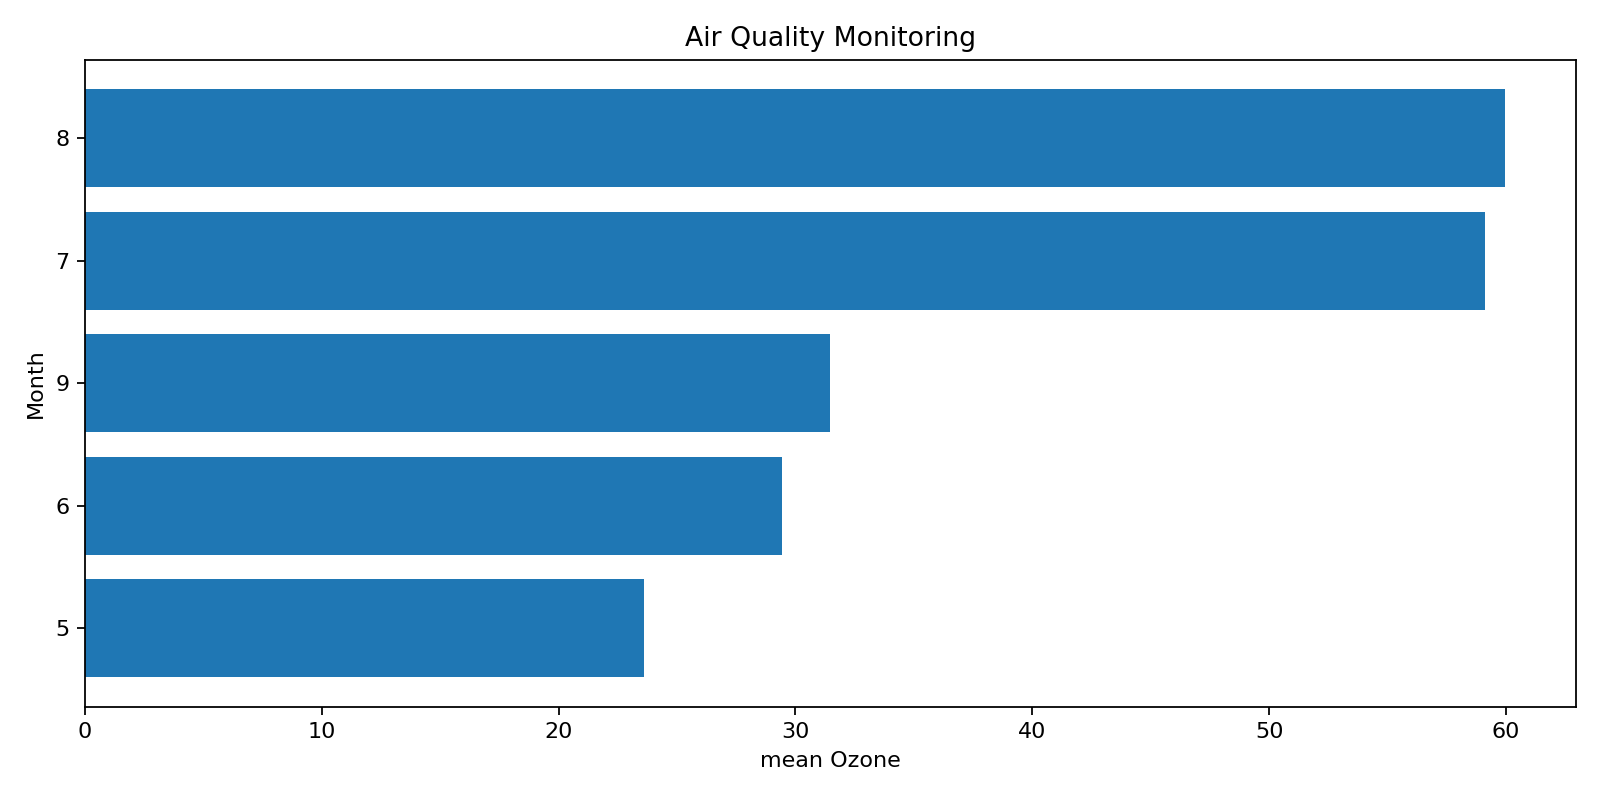

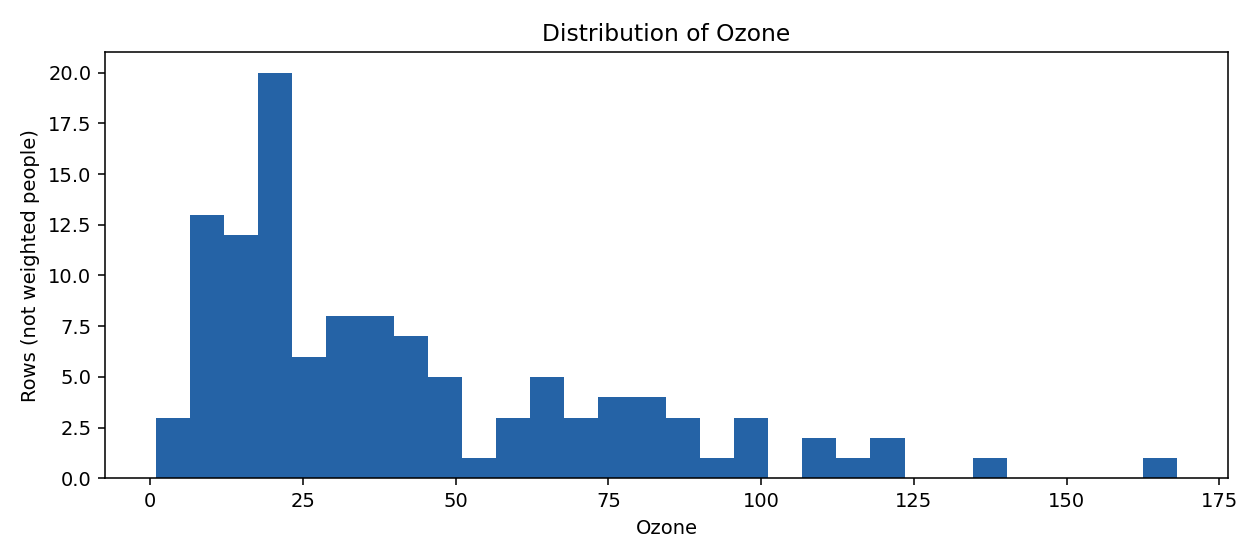

In [4]:
display(Image(filename="outputs/main_chart.png"))
display(Image(filename="outputs/distribution.png"))

## Interpretation
New York 1973 summer observations contain missing measurements and serial dependence.

**Next action:** Inspect monitoring coverage before comparing months.

Read outputs/REPORT.md for executed findings. This project does not establish causation or a production decision rule.